# 05 Pricing and risk of the proxy revenue swap

The base case is a 10-year PRS on Pen y Cymoedd starting 1 January 2027,
settled monthly. Each month the hedge provider (the counterparty) collects
the proxy revenue `sum_h proxy_MWh_h x price_h` and pays the farm a fixed
`K x E[proxy volume that month]`. The farm gets a predictable wholesale
income. It still carries operational risk: downtime, curtailment, or simply
running below the agreed efficiency.

Assumptions: a GBP 75/MWh baseload forward for every year, a flat 4.5%
discount rate, and the hourly Market Index price as the reference. The
simulations all run on the C++ engine; notebook 06 checks it against the
Python version.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # make src/prs importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prs.plotting import fig, use_style, label_end, BLUE, ORANGE, AQUA, GREY
use_style()
pd.set_option("display.precision", 3)

In [2]:
from prs.pipeline import load_models
from prs.pricing import (Contract, strike_terms, counterparty_pnl, risk_report,
                         risk_premium, summary, stress_inputs)
from prs.engine import simulate_monthly_cpp
import time

m = load_models()
c = Contract()
models = (m["wind"], m["power"], m["price"])
def run(n, contract=c, seed=0, **kw):
    return simulate_monthly_cpp(*models, contract, n, seed=seed, **kw)

t = time.time()
base = run(10_000)
print(f"10,000 paths x {len(c.index()):,} hours in {time.time()-t:.1f}s")
terms = strike_terms(base, c)
pd.Series(summary(base, terms, c)).round(3).to_frame("base case")

10,000 paths x 87,672 hours in 24.9s


,base case
fair_fixed_price_gbp_mwh,67.927
volume_weighted_baseload_gbp_mwh,76.710
capture_rate,0.886
expected_annual_volume_gwh,630.277
annual_volume_p90_gwh,574.355
annual_volume_p10_gwh,686.564
expected_capacity_factor,0.315


## Fair fixed price and the capture discount

The fair fixed price is the discounted expected capture price, meaning what
each MWh of proxy output should earn on average. It comes out about 11%
below the volume-weighted baseload price. That gap is cannibalisation
again: the farm produces most when the rest of the GB fleet does, and those
are the cheapest hours. A provider who priced the swap straight off the
baseload forward would overpay by roughly GBP 9/MWh.

Text(0.0, 1.0, 'The farm sells most when prices are lowest (simulated)')

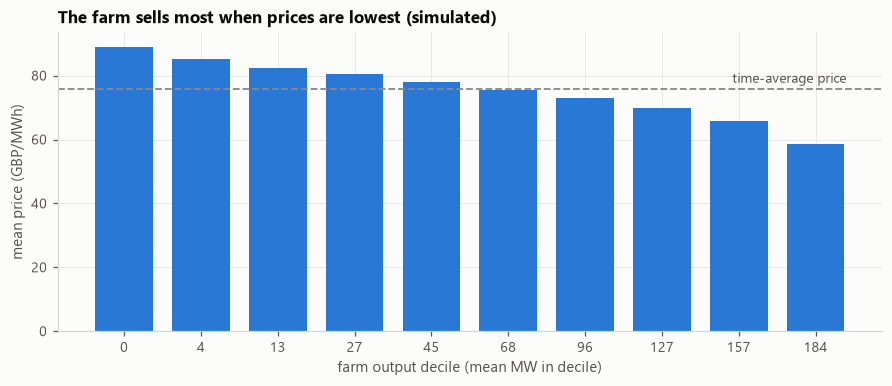

In [3]:
idx = c.index()[:8760 * 2]
ws, cf = m["wind"].simulate(idx, 50, seed=11)
p = m["price"].simulate(idx, cf, forward=c.forward, seed=12)
mw = m["power"].predict_mw(ws)
df = pd.DataFrame({"mw": mw.ravel(), "p": p.ravel()})
df["bin"] = pd.qcut(df["mw"], 10, labels=False, duplicates="drop")
g = df.groupby("bin").agg(mw=("mw", "mean"), price=("p", "mean"))
f, ax = fig(figsize=(8, 3.4))
ax.bar(g.index, g["price"], color=BLUE, width=0.75)
ax.axhline(df["p"].mean(), color=GREY, lw=1.2, ls="--")
ax.text(g.index[-1] + 0.4, df["p"].mean() + 1, "time-average price", ha="right", va="bottom", fontsize=9, color="#52514e")
ax.set_xticks(g.index, [f"{v:.0f}" for v in g["mw"]])
ax.set_xlabel("farm output decile (mean MW in decile)"); ax.set_ylabel("mean price (GBP/MWh)")
ax.set_title("The farm sells most when prices are lowest (simulated)")

## Counterparty P&L

I look at this two ways. Unhedged is the swap on its own. Hedged means the
counterparty also sells baseload forwards for the expected volume each
month. The forwards take care of the overall price level. What's left is
volume risk (how windy it is) and shape risk (whether the wind blows in
cheap or expensive hours), and you can't hedge those with standard
products.

mean     sd  VaR95   ES95  VaR99   ES99
unhedged PV lifetime  0.00  19.71  32.13  40.27  45.36  51.53
         Year 1      -0.03   6.31  10.09  12.41  13.84  15.71
hedged   PV lifetime  0.00   8.61  14.21  17.88  20.15  23.28
         Year 1      -0.03   3.33   5.49   6.93   7.79   9.14

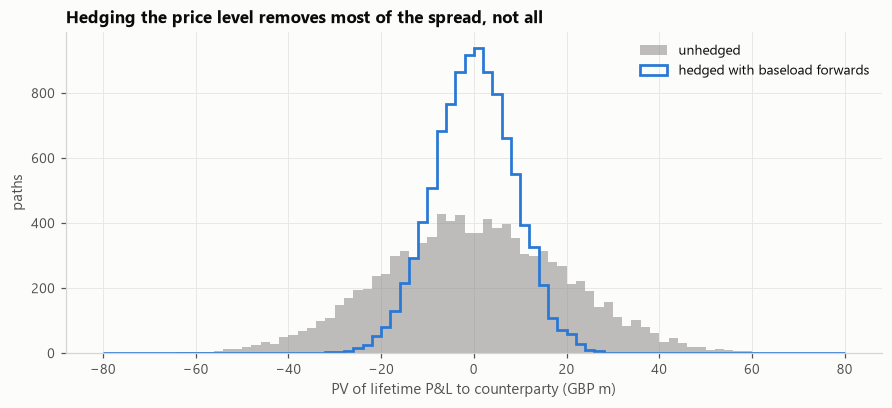

In [4]:
pnl = counterparty_pnl(base, terms, c)
D = c.discount_factors()
pv = {k: (v * D).sum(1) / 1e6 for k, v in pnl.items()}
f, ax = fig(figsize=(8, 3.6))
bins = np.linspace(-80, 80, 81)
ax.hist(pv["unhedged"], bins=bins, color=GREY, alpha=0.55, lw=0, label="unhedged")
ax.hist(pv["hedged"], bins=bins, histtype="step", color=BLUE, lw=1.8, label="hedged with baseload forwards")
ax.set_xlabel("PV of lifetime P&L to counterparty (GBP m)"); ax.set_ylabel("paths")
ax.set_title("Hedging the price level removes most of the spread, not all")
ax.legend()
pd.concat({k: risk_report(v, c) for k, v in pnl.items()}).round(2)

Losses are shown as positive numbers, VaR and ES at 95% and 99%, in GBP m.
Hedging more than halves the lifetime risk. Whatever remains is the risk
the counterparty is actually being paid to carry.

## Risk premium

In practice a trading desk holds capital against risk it can't hedge and
charges for tying it up. I've kept the version here simple: capital is the
99% expected shortfall of one year's hedged P&L, held for every year of the
deal and charged at an 8% hurdle rate, then spread over the expected
discounted volume.

In [5]:
prem = risk_premium(base, terms, c)
pd.Series(prem).round(2).to_frame("value")

,value
capital_gbp_m,9.13
premium_pv_gbp_m,5.78
premium_gbp_per_mwh,1.14
quoted_fixed_price,66.79


That works out at a quote about GBP 1/MWh below the fair price, so a
premium under 2%. That's smaller than I expected. It fits with how PRS deals
are sold, as cheaper than a PPA that guarantees volume, because a lot of
the weather risk averages out over 120 monthly settlements.

## Stress tests

These are year-1 shocks that hit after the deal is signed, so the fixed
price and the hedges stay at their base-case values.

- Still winter: January, February and December 2027 are as calm as the
  calmest winter on record (1963/64), for both site and national wind.
- Gas shock: year-1 prices rise by the gap between 2022 and the
  post-crisis average, about GBP 122/MWh.
- Both at once.
- Steeper cannibalisation: the wind-price slope times 1.5, as a rough
  stand-in for a GB with a lot more wind.

In [6]:
st = m["stress"]
scenarios = {
    "base": {},
    "still winter": stress_inputs(c, still_winter_shift=st["still_winter_shift"]),
    "gas shock": stress_inputs(c, gas_shift=st["gas_shift"]),
    "still winter + gas shock": stress_inputs(c, still_winter_shift=st["still_winter_shift"], gas_shift=st["gas_shift"]),
    "cannibalisation x1.5": {"cannibal_mult": 1.5},
}
rows = {}
for name, kw in scenarios.items():
    s = run(4000, seed=7, **kw)
    p = counterparty_pnl(s, terms, c)
    y1 = {k: v[:, :12].sum(1) / 1e6 for k, v in p.items()}
    rows[name] = {"year-1 volume (GWh)": s["volume"][:, :12].sum(1).mean() / 1000,
                  "year-1 baseload (GBP/MWh)": s["baseload"][:, :12].mean(),
                  "unhedged mean P&L": y1["unhedged"].mean(),
                  "hedged mean P&L": y1["hedged"].mean(),
                  "hedged 1-in-20 loss": -np.quantile(y1["hedged"], 0.05)}
stress = pd.DataFrame(rows).T
stress.round(2)

,year-1 volume (GWh),year-1 baseload (GBP/MWh),unhedged mean P&L,hedged mean P&L,hedged 1-in-20 loss
base,629.94,75.50,-0.01,0.01,5.36
still winter,567.40,77.76,-3.69,-5.51,11.21
gas shock,629.94,197.35,76.75,0.08,13.78
still winter + gas shock,567.40,199.62,65.45,-13.06,26.70
cannibalisation x1.5,629.94,62.13,-11.82,-2.84,7.31


Text(0.0, 1.0, "A calm winter during a gas shock is the hedged desk's worst case")

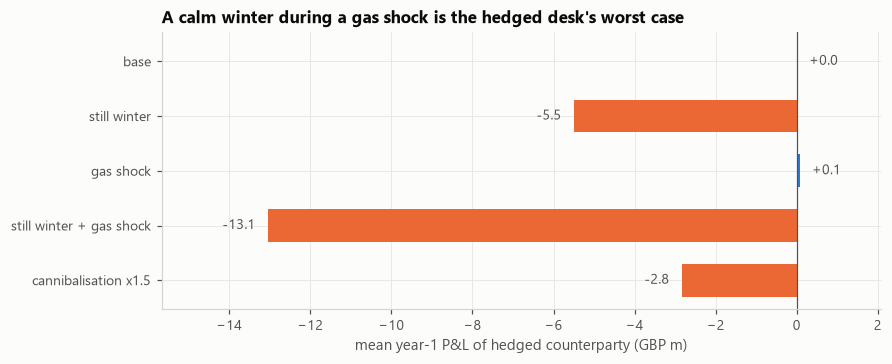

In [7]:
f, ax = fig(figsize=(8, 3.2))
vals = stress["hedged mean P&L"]
colors = [GREY if n == "base" else (ORANGE if v < 0 else BLUE) for n, v in vals.items()]
ax.barh(vals.index[::-1], vals.values[::-1], color=colors[::-1], height=0.6)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlim(vals.min() * 1.2, max(vals.max(), 0) + 2)   # room for the value labels
for y, v in enumerate(vals.values[::-1]):
    ax.text(v + (0.3 if v >= 0 else -0.3), y, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=9, color="#52514e")
ax.set_xlabel("mean year-1 P&L of hedged counterparty (GBP m)")
ax.set_title("A calm winter during a gas shock is the hedged desk's worst case")

On its own, the gas shock is a large gain for an unhedged counterparty,
since it's collecting revenue at high prices. Hedged, it's roughly neutral,
which is exactly what the forwards are for.

A still winter on its own costs a few million. Volume falls, though calm
winters are also a bit pricier, which softens the blow.

Both together is the scenario that hurts. The hedged desk has sold forward
power it expects the farm to generate. The farm doesn't generate it, so the
desk has to buy that power back in the middle of a price spike. The two
shocks feed off each other, and the loss ends up well over twice the
still-winter loss alone.

Steeper cannibalisation is a slower problem. The fixed price was set using
today's wind-price slope, and every year the real slope is steeper the
counterparty collects less than it planned for.

## Sensitivities

,0,1,2,3,4
forward,55.00,65.00,75.00,85.00,95.00
fair_fixed,47.94,57.94,67.94,77.94,87.94


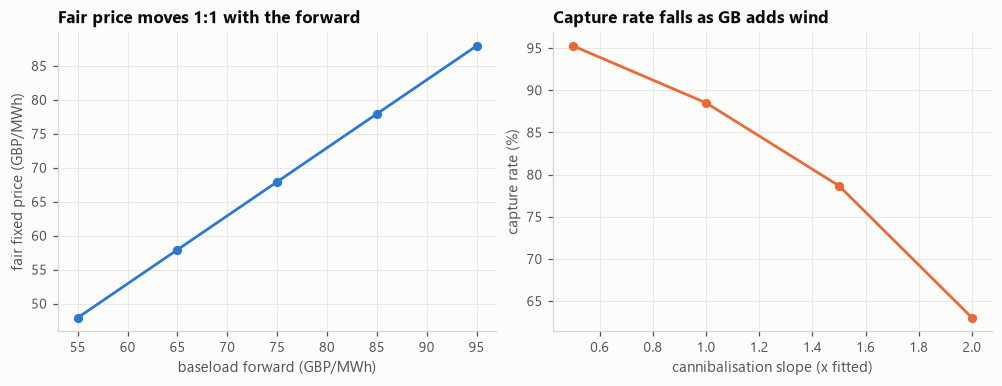

In [8]:
short = Contract(years=3)
fwds = [55, 65, 75, 85, 95]
fair = []
for F in fwds:
    cc = Contract(years=3, forward=F)
    s = run(1500, contract=cc, seed=3)
    fair.append(strike_terms(s, cc).fixed_price)
mults = [0.5, 1.0, 1.5, 2.0]
capture = []
for k in mults:
    s = run(1500, contract=short, seed=3, cannibal_mult=k)
    capture.append(summary(s, strike_terms(s, short), short)["capture_rate"])
f, axes = fig(1, 2, figsize=(9, 3.4))
axes[0].plot(fwds, fair, "o-", color=BLUE, ms=5)
axes[0].set_xlabel("baseload forward (GBP/MWh)"); axes[0].set_ylabel("fair fixed price (GBP/MWh)")
axes[0].set_title("Fair price moves 1:1 with the forward")
axes[1].plot(mults, np.array(capture) * 100, "o-", color=ORANGE, ms=5)
axes[1].set_xlabel("cannibalisation slope (x fitted)"); axes[1].set_ylabel("capture rate (%)")
axes[1].set_title("Capture rate falls as GB adds wind")
pd.DataFrame({"forward": fwds, "fair_fixed": fair}).round(2).T

## Policy angle: farms coming off subsidy

Pen y Cymoedd started generating in 2017. As far as I can tell it's
supported by the Renewables Obligation (RO), which closed to new capacity
that year, though I haven't confirmed it on Ofgem's register yet. RO
certificates are paid on top of the wholesale price for 20 years, so for
this farm they run to about 2037. The swap only covers the wholesale side,
so it leaves that income alone.

Lots of GB wind farms from the RO era will hit the end of their 20 years
from the late 2020s onwards. After that they're fully exposed to the
market, and the wholesale risk in this notebook becomes their whole revenue
risk. Two things stand out to me.

First, the year-to-year swings in revenue are big. Here's the farm's annual
wholesale revenue with and without the swap:

merchant revenue: 10th pct 34.8, median 42.7, 90th pct 51.0 GBP m/yr; PRS fixed 42.8


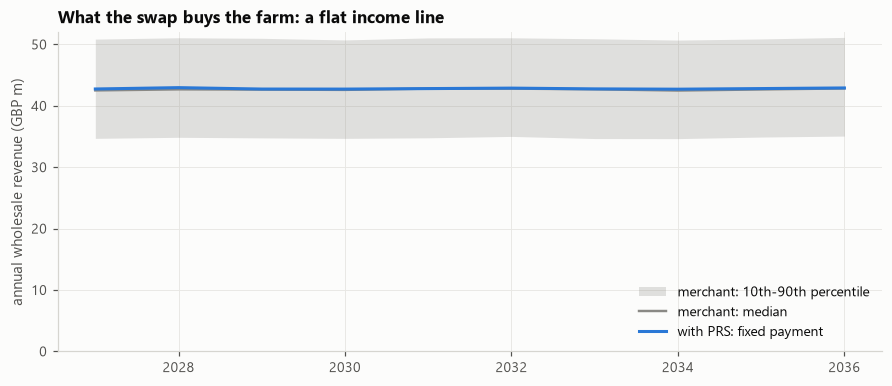

In [9]:
rev_y = base["revenue"].reshape(-1, c.years, 12).sum(2) / 1e6
fixed_y = (terms.fixed_price * terms.exp_volume).reshape(c.years, 12).sum(1) / 1e6
q = np.percentile(rev_y, [10, 50, 90], axis=0)
years = np.arange(2027, 2027 + c.years)
f, ax = fig(figsize=(8, 3.4))
ax.fill_between(years, q[0], q[2], color=GREY, alpha=0.25, lw=0, label="merchant: 10th-90th percentile")
ax.plot(years, q[1], color=GREY, lw=1.6, label="merchant: median")
ax.plot(years, fixed_y, color=BLUE, lw=2, label="with PRS: fixed payment")
ax.set_ylabel("annual wholesale revenue (GBP m)"); ax.set_ylim(0, None)
ax.set_title("What the swap buys the farm: a flat income line")
ax.legend(loc="lower right")
print(f"merchant revenue: 10th pct {q[0].mean():.1f}, median {q[1].mean():.1f}, 90th pct {q[2].mean():.1f} GBP m/yr; PRS fixed {fixed_y.mean():.1f}")

Second, cannibalisation wears value down over time. Each extra GW of wind
on the system deepens the price dip on windy days, so a merchant farm's
capture rate can fall even while average prices hold steady. A long PRS
hands that structural risk to the counterparty. That's why I think the
cannibalisation assumption deserves as much scrutiny as the wind model
itself.

On the policy side, this points to two things: GB needs liquid, shaped
hedging products, so farms coming off subsidy can refinance without taking
full market risk; and any assessment of repowering or extending the life of
RO-era farms without new support has to treat cannibalisation explicitly.

## Limitations

- The price shape and wind slope come from Jul 2023 - Dec 2025 only. The
  slope probably gets steeper when gas is expensive; here it's fixed.
- National wind is transmission-metered FUELHH output, so embedded wind is
  missing, and capacity is a rolling-max proxy.
- There's no random multi-year trend in the price level (gas, basically).
  It only comes in through the forward I set and the gas-shock stress.
- Hourly spikes above about GBP 300/MWh are under-represented (see
  notebook 04).
- After bias correction, the farm cuts out at about 21 m/s of ERA5 wind.
  Hours that windy are too rare in the metered data to check.